# Forecasting the Brent-WTI Spread Using Oil Market Fundamentals

# 1. Introduction

## 1.1 Economic and financial context

In the global energy commodity market, West Texas Intermediate (WTI) and North Sea Brent are the two main benchmark prices for light sweet crude oil. 

WTI is the American benchmark crude. It is a light, sweet crude oil produced primarily in West Texas and New Mexico. Its physical delivery point is Cushing, Oklahoma, a landlocked pipeline hub in the middle of the United States.

Brent crude is the international benchmark. It aggregates production from several North Sea fields and it has direct access to waterborne global markets.

Historically, due to a slightly lower sulfur content and a more advantageous API density, WTI was traded with a slight premium for quality (1 to 2 USD/barrel) compared to Brent. However, this changed in late 2010. In the United States, the shale oil revolution, combined with insufficient pipeline infrastructure to transport crude to refineries in the Gulf of Mexico and a historic ban on exporting US crude (lifted in late 2015), led to massive saturation of the Cushing storage hub.

This logistical bottleneck caused an unprecedented disconnection between the two prices, permanently reversing the dynamic: the Brent reached a record premium of nearly 30 USD/barrel compared to WTI. Although the spread has narrowed with the construction of new transmission capacity and the opening up of US export flows, the Brent-WTI spread remains characterized by high temporal volatility. For market operators, refiners and systematic fund managers, modeling and anticipating changes in this gap represents a major financial and industrial issue.

## 1.2 Problem and objectives of the project

This project aims to answer the following empirical question: Does the integration of fundamental physical variables (stocks, production, trade flows, and refining) in the United States and Europe improve the forecast of the one-month change in the Brent-WTI spread, compared to models based exclusively on the dynamics of past prices?

The objective is not to identify structural causal relationships in a macroeconometric sense, but to assess the out-of-sample predictive capacity of these physical signals using regularized statistical and machine learning algorithms.

## 1.3 Project contributions and summary of the main empirical results

## 1.4 Literature review

Our project is based on two recent academic contributions on the determinants of the Brent-WTI spread.

### 1.4.1 Geyer-Klingeberg and Rathgeber (2020)

In their paper titled "Determinants of the WTI-Brent price spread revisited" (Journal of Futures Markets, 2020), Jerome Geyer-Klingeberg and Andreas W. Rathgeber examine the spread drivers over a period from 1995 to 2019. In this article, the authors demonstrate that the convenience yield, which serves as a direct indicator of the scarcity of available physical stocks, is a fundamental historical determinant of the spread. This finding directly motivates our study to include inventory levels and changes in order to capture physical market tightness.

### 1.4.2 Sifat, Zarei and Mand (2022)

In a study entitled "Revisiting WTI–Brent spread and its drivers" (Energy, 2022), Imtiaz Sifat, Alireza Zarei and Abdollah Ah Mand further examine the determinants of the WTI-Brent spread over the 1988-2020 period using data from the EIA and Refinitiv Eikon. According to them, variables related to global and local demand, and crude imports from Canada have an effect on the spread. This is why in our project, we include export and import variables.

## 1.5 Imports and project paths

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from scripts.cleaning import clean_eia_prices, clean_jodi_oil
from scripts.plot import plot_spot_prices, plot_spread
from scripts.features import build_monthly_price_features, build_model_dataset
from scripts.tests import check_missing_values, last_complete_date, summarize_model_sample
from scripts.models import (
    get_models,
    forecast_metrics,
    run_overfitting_diagnostics,
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from lightgbm import LGBMRegressor
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from scripts.ensemble import build_rolling_stacking, add_ensembles_to_diagnostics

We define the project directory structure and the locations of raw and processed datasets.

In [2]:
PROJECT_DIR = Path.cwd()
RAW_EIA_DIR = PROJECT_DIR / "data" / "EIA"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

BRENT_FILE = RAW_EIA_DIR / "spot_brent.csv"
WTI_FILE = RAW_EIA_DIR / "spot_wti.csv"
JODI_DIR = PROJECT_DIR / "data" / "JODI"

JODI_CLEAN_FILE = PROCESSED_DIR / "jodi_oil_clean.csv"
CLEAN_PRICES_FILE = PROCESSED_DIR / "eia_spot_prices_clean.csv"
MONTHLY_PRICE_FEATURES_FILE = PROCESSED_DIR / "monthly_price_features.csv"
MODEL_DATASET_FILE = PROCESSED_DIR / "model_dataset.csv"

# 2. Dataset for the project

Our empirical dataset is composed of monthly spot price series for Brent and WTI sourced from the EIA, and monthly physical oil balance data from the JODI Oil database, spanning from April 2003 to June 2026 (279 continuous monthly observations). 

## 2.1 EIA Spot Prices

This section loads and cleans the daily Brent and WTI spot price series from the EIA data.

The two daily price series are merged on common trading dates and saved as a cleaned dataset.

In [3]:
prices = clean_eia_prices(
    brent_path=BRENT_FILE,
    wti_path=WTI_FILE,
    output_path=CLEAN_PRICES_FILE,
)

prices.head()

,date,Brent,WTI
0,1987-05-20,18.63,19.75
1,1987-05-21,18.45,19.95
2,1987-05-22,18.55,19.68
3,1987-05-26,18.63,19.35
4,1987-05-27,18.60,19.38


We first plot the Brent and WTI spot prices and the Brent-WTI spread to inspect the main dynamics of the series.

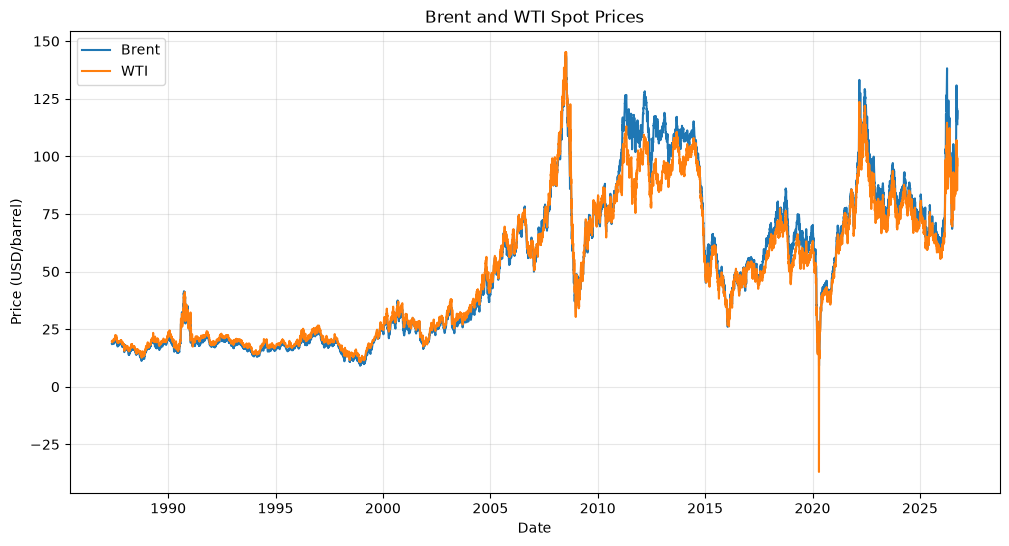

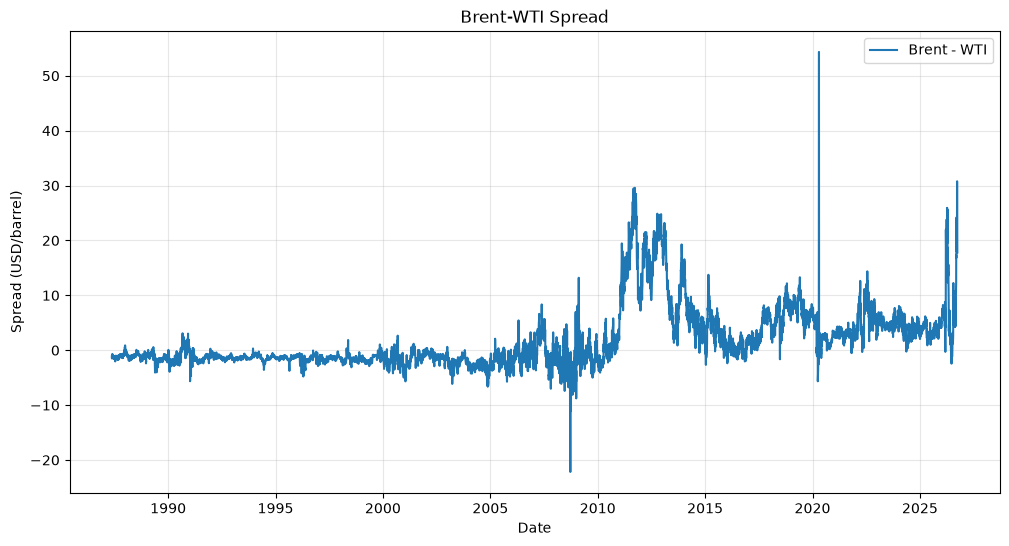

In [4]:
plot_spot_prices(prices)
plot_spread(prices)

The plots show that Brent and WTI spot prices generally move together, driven by global oil supply and demand. However, the spread between them shows distinct periods:

- Before 2010: The spread was small and stable near zero, with WTI often trading slightly higher than Brent due to its better quality.

- 2011-2015: The US shale boom created an oil surplus trapped at the Cushing storage hub. Because this oil could not easily reach coastal refineries or be exported, WTI dropped significantly, and the Brent premium increased.

- After 2015: New pipelines and the end of the US crude export ban reconnected the two markets. The spread narrowed, but Brent has maintained a regular premium between 0 to 10 USD/barrel, with frequent ups and downs.

## 2.2 JODI Oil Fundamentals

This section loads and cleans monthly oil market fundamentals from the JODI Oil database.

JODI data are reported by country, month, energy product, flow variable, unit of measurement, and observed value.

### 2.2.1 Country selection

We separate countries into two groups: countries related to the WTI market and countries related to the Brent market.

### WTI-related countries

The WTI benchmark is mainly linked to the North American oil market. We therefore keep:

- United States (`US`)
- Canada (`CA`)

### Brent-related countries

The Brent benchmark is more closely linked to the European and North Sea oil market. We therefore keep:

- United Kingdom (`GB`)
- Norway (`NO`)
- Netherlands (`NL`)
- Belgium (`BE`)

We include the United Kingdom and Norway because the offshore North Sea oil fields underlying the Brent basket are located within their maritime territorial waters, and the Netherlands and Belgium because they host the Amsterdam-Rotterdam-Antwerp refining, trading and storage hub.

### 2.2.2 JODI variables

The main JODI variables used in the project are:

- Closing stock levels: crude oil inventories at the end of the month.
- Stock changes: monthly changes in crude oil inventories.
- Indigenous production: domestic crude oil production.
- Total imports: crude oil imported by the country.
- Total exports: crude oil exported by the country.
- Refinery intake: crude oil used as input by refineries.

These variables describe the main components of the oil market balance: inventories, production, international trade, and refinery demand.

In [5]:
WTI_COUNTRIES = ["US", "CA"]

BRENT_COUNTRIES = ["GB", "NO", "NL", "BE"]

JODI_COUNTRIES = WTI_COUNTRIES + BRENT_COUNTRIES

In [6]:
jodi = clean_jodi_oil(
    input_dir=JODI_DIR,
    output_path=JODI_CLEAN_FILE,
    countries=JODI_COUNTRIES,
)

jodi.head()

variable,date,BE_CLOSTLV,BE_INDPROD,BE_REFINOBS,BE_STOCKCH,BE_TOTEXPSB,BE_TOTIMPSB,CA_CLOSTLV,CA_INDPROD,CA_REFINOBS,...,NO_REFINOBS,NO_STOCKCH,NO_TOTEXPSB,NO_TOTIMPSB,US_CLOSTLV,US_INDPROD,US_REFINOBS,US_STOCKCH,US_TOTEXPSB,US_TOTIMPSB
0,2002-01-01,4974.75,0.0,635.7219,523.27,0.0,650.6997,41338.33,1691.7006,1573.0284,...,279.3045,9647.33,2463.0019,17.3961,787774.0,5847.5806,14486.8710,5135.0,10.9355,8708.5484
1,2002-02-01,4775.76,0.0,604.8664,-198.99,0.0,598.0229,43070.28,1768.0750,1561.3250,...,280.0725,-1031.80,3002.6875,6.4200,802419.0,5871.3571,14306.1071,14645.0,4.4286,8753.3571
2,2002-03-01,4038.76,0.0,628.8274,-737.00,0.0,604.8155,45222.32,1789.4413,1521.5568,...,265.5326,-9603.11,2860.9384,0.0000,808272.0,5883.4516,14525.7419,5853.0,8.1935,8799.3871
3,2002-04-01,4267.23,0.0,678.5313,228.47,0.0,686.3927,47440.69,1822.0447,1398.7547,...,253.6613,4915.79,2960.7970,10.9853,809567.0,5858.7000,15325.1667,1295.0,7.6000,9300.8000
4,2002-05-01,4267.23,0.0,683.9835,0.00,0.0,683.7458,44735.90,1798.2426,1505.9523,...,267.4655,2785.86,2607.7281,19.5706,816316.0,5923.7097,15300.6452,6749.0,7.2258,9323.4194


## 2.3 Monthly Feature Engineering

The forecasting models are built at a monthly frequency.

The EIA Brent and WTI prices are originally daily, while JODI fundamentals are monthly. We therefore convert the daily spot prices into monthly observations and then merge them with monthly JODI fundamentals.

For each month, the price observation is defined at the first calendar day of the month. If that date is not available in the daily price data, we use the last available trading price before that date. This gives a monthly price series that can be interpreted as information available at the beginning of the month.

In [7]:
monthly_prices = build_monthly_price_features(
    prices=prices,
    output_path=MONTHLY_PRICE_FEATURES_FILE,
)

monthly_prices.head()

,date,Brent,WTI,spread,brent_return,wti_return,spread_change,spread_return,spread_lag_1,spread_change_lag_1,...,wti_return_rolling_mean_12,spread_return_rolling_mean_12,brent_return_rolling_vol_3,wti_return_rolling_vol_3,spread_return_rolling_vol_3,brent_return_rolling_vol_12,wti_return_rolling_vol_12,spread_return_rolling_vol_12,brent_wti_corr_12,target_spread_change_next_month
0,1987-06-01,18.65,19.55,-0.90,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.59
1,1987-07-01,18.98,20.47,-1.49,0.017694,0.047059,-0.59,-0.029364,-0.90,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.09
2,1987-08-01,20.03,21.43,-1.40,0.055321,0.046898,0.09,0.008423,-1.49,-0.59,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.22
3,1987-09-01,18.43,19.61,-1.18,-0.079880,-0.084928,0.22,0.005047,-1.40,0.09,...,NaN,NaN,0.241727,0.263812,0.072436,NaN,NaN,NaN,NaN,0.06
4,1987-10-01,18.50,19.62,-1.12,0.003798,0.000510,0.06,0.003288,-1.18,0.22,...,NaN,NaN,0.236373,0.231644,0.009040,NaN,NaN,NaN,NaN,-0.06


In [8]:
monthly_prices.columns.tolist()

['date',
 'Brent',
 'WTI',
 'spread',
 'brent_return',
 'wti_return',
 'spread_change',
 'spread_return',
 'spread_lag_1',
 'spread_change_lag_1',
 'brent_return_lag_1',
 'wti_return_lag_1',
 'spread_return_lag_1',
 'spread_lag_2',
 'spread_change_lag_2',
 'brent_return_lag_2',
 'wti_return_lag_2',
 'spread_return_lag_2',
 'spread_lag_3',
 'spread_change_lag_3',
 'brent_return_lag_3',
 'wti_return_lag_3',
 'spread_return_lag_3',
 'spread_change_rolling_mean_6',
 'brent_return_rolling_mean_6',
 'wti_return_rolling_mean_6',
 'spread_return_rolling_mean_6',
 'spread_change_rolling_mean_12',
 'brent_return_rolling_mean_12',
 'wti_return_rolling_mean_12',
 'spread_return_rolling_mean_12',
 'brent_return_rolling_vol_3',
 'wti_return_rolling_vol_3',
 'spread_return_rolling_vol_3',
 'brent_return_rolling_vol_12',
 'wti_return_rolling_vol_12',
 'spread_return_rolling_vol_12',
 'brent_wti_corr_12',
 'target_spread_change_next_month']

## 2.4 Merge with lagged and stationary JODI fundamentals

We merge monthly price features with transformed JODI fundamentals with two adjustments:

1. Publication Lag ($M-2$): Fundamentals are lagged by two months to match JODI's official reporting delay and prevent look-ahead bias.
2. Stationarity & Integration Balance: Raw physical levels (stocks, production, refining) are non-stationary $I(1)$ series. Regressing our stationary target ($I(0)$) on $I(1)$ levels creates an unbalanced regression and prevents decision trees from extrapolating. We therefore transform them into stationary $I(0)$ features (mainly YoY growth rates).

In [9]:
model_data = build_model_dataset(
    monthly_prices=monthly_prices,
    jodi=jodi,
    output_path=MODEL_DATASET_FILE,
    jodi_lag=2,
    stationarize=True
)

We perform Augmented Dickey-Fuller tests to confirm the integration order of our variables

In [10]:
def adf_summary(series, name, regression="c"):
    s = series.dropna()
    res = adfuller(s, regression=regression, autolag="AIC", result_object=False)
    
    spec_label = "Trend + Const (ct)" if regression == "ct" else "Const (c)"
    
    return {
        "Variable": name,
        "Specification": spec_label,
        "ADF Stat": round(res[0], 3),
        "p-value": round(res[1], 4),
        "Stationary (5%)": "Yes (I(0))" if res[1] < 0.05 else "No (I(1))"
    }

adf_table = pd.DataFrame([
    adf_summary(model_data["spread"], "Spread Level (Raw)", regression="c"),
    adf_summary(model_data["target_spread_change_next_month"], "Target: Spread Change (dSpread)", regression="c"),
    adf_summary(jodi["US_CLOSTLV"], "US Stocks (Raw JODI Level)", regression="c"),
    adf_summary(model_data["US_CLOSTLV_yoy"], "US Stocks YoY (Transformed)", regression="c"),
    adf_summary(jodi["US_INDPROD"], "US Production (Raw JODI Level)", regression="c"),
    adf_summary(jodi["US_INDPROD"], "US Production (Raw JODI Level)", regression="ct"),
    adf_summary(model_data["US_INDPROD_yoy"], "US Production YoY (Transformed)", regression="c"),
])

display(adf_table)

,Variable,Specification,ADF Stat,p-value,Stationary (5%)
0,Spread Level (Raw),Const (c),-2.455,0.1269,No (I(1))
1,Target: Spread Change (dSpread),Const (c),-9.150,0.0000,Yes (I(0))
2,US Stocks (Raw JODI Level),Const (c),-0.609,0.8689,No (I(1))
3,US Stocks YoY (Transformed),Const (c),-3.230,0.0183,Yes (I(0))
4,US Production (Raw JODI Level),Const (c),0.330,0.9787,No (I(1))
5,US Production (Raw JODI Level),Trend + Const (ct),-2.685,0.2426,No (I(1))
6,US Production YoY (Transformed),Const (c),-3.000,0.0349,Yes (I(0))


### Discussion of Stationarity Diagnostics (ADF Tests)

1. Stationary target ($I(0)$): The one-month-ahead spread change ($\Delta S_{t+1}$) is strictly stationary ($p\text{-value} < 0.0001$), while the raw spread level is non-stationary ($p = 0.1269$).
2. Non-stationary raw fundamentals ($I(1)$): US inventories and production exhibit strong unit-root trends. Regressing a stationary target on non-stationary levels leads to econometric imbalance in linear models and prevents decision trees from extrapolating out-of-sample.
3. Validation of the transformation ($I(0)$): Transforming levels into 12-month percentage changes removes structural trends and seasonal cycles. Both transformed US inventories ($p = 0.0183$) and production ($p = 0.0349$) are confirmed stationary at the 5% level.

Matching an $I(0)$ target with $I(0)$ predictors ensures valid inference and stable out-of-sample machine learning performance.

## 2.5 Modelling Sample

This section defines the final dataset used for the forecasting models.

We define the prediction target, the different feature sets, the modelling period, and we check for missing values before running the rolling-window forecasts.

The target variable is the one-month-ahead change in the Brent-WTI spread:

```text
target_{t+1} = spread_{t+1} - spread_t
```

A positive value means that the spread widened during the following month, while a negative value means that the spread narrowed.

In [11]:
TARGET_COL = "target_spread_change_next_month"

We first define the set of price-based predictors. These variables are computed only from past Brent and WTI prices.

They include spread levels, returns, lagged values, rolling means, rolling volatilities, and rolling correlations.

In [12]:
PRICE_FEATURES = [
    "spread_lag_1",                 # Mean-reversion anchor
    "spread_change_lag_1",          # Short-term spread momentum
    "spread_return_lag_1",          # Normalized relative return momentum
    "spread_change_rolling_mean_6", # Medium-term seasonal trend
    "spread_return_rolling_mean_12",# Annual trend
    "brent_return_lag_1",           # Brent-specific short shock
    "wti_return_lag_1",             # WTI-specific short shock
    "spread_return_rolling_vol_12", # Spread risk regime
    "brent_return_rolling_vol_12",  # Brent volatility
    "wti_return_rolling_vol_12",    # WTI volatility
    "brent_wti_corr_12",            # Market integration/decoupling
]

We now define the JODI fundamental variables by geographical group.

The WTI-related fundamentals are based on North American countries, while the Brent-related fundamentals are based on European and North Sea countries.

In [13]:
# WTI Hub: United States (Cushing) and Canada (major pipeline flows)
WTI_PREFIXES = ["US_", "CA_"]

# Brent Hub: UK & Norway (North Sea fields), Netherlands & Belgium (ARA refining hub)
BRENT_PREFIXES = ["GB_", "NO_", "NL_", "BE_"]

WTI_FUNDAMENTAL_FEATURES = [
    col for col in model_data.columns
    if any(col.startswith(prefix) for prefix in WTI_PREFIXES)
]

BRENT_FUNDAMENTAL_FEATURES = [
    col for col in model_data.columns
    if any(col.startswith(prefix) for prefix in BRENT_PREFIXES)
]

ALL_FUNDAMENTAL_FEATURES = (
    WTI_FUNDAMENTAL_FEATURES
    + BRENT_FUNDAMENTAL_FEATURES
)

We compare four information sets:

1. price features only;
2. price features plus WTI-related fundamentals;
3. price features plus Brent-related fundamentals;
4. price features plus all fundamentals.

This allows us to test whether JODI fundamentals improve forecasting performance and whether the improvement comes mainly from one geographical group.

In [14]:
FEATURE_SETS = {
    "prices_only": PRICE_FEATURES,
    "prices_wti_fundamentals": PRICE_FEATURES + WTI_FUNDAMENTAL_FEATURES,
    "prices_brent_fundamentals": PRICE_FEATURES + BRENT_FUNDAMENTAL_FEATURES,
    "prices_all_fundamentals": PRICE_FEATURES + ALL_FUNDAMENTAL_FEATURES,
}

In [15]:
for name, features in FEATURE_SETS.items():
    print(f"{name}: {len(features)} features")

prices_only: 11 features
prices_wti_fundamentals: 23 features
prices_brent_fundamentals: 35 features
prices_all_fundamentals: 47 features


The modelling sample starts in April 2003. 

Although JODI data begin in January 2002, computing 12-month YoY percentage changes requires 12 months of initialization, and applying the 2-month publication lag shifts the first fully observed fundamental features to April 2003. 

The end date is set to the last month for which all selected JODI variables are available. 

In [16]:
START_DATE = "2003-04-01"

JODI_FEATURES = [
    col for col in model_data.columns
    if col not in monthly_prices.columns
]

END_DATE = last_complete_date(
    data=model_data,
    columns=JODI_FEATURES,
)

print("Modelling Sample Range:", START_DATE, "to", END_DATE)

Modelling Sample Range: 2003-04-01 to 2026-06-01 00:00:00


Before running the models, we check missing values in the price features, JODI features, and target variable over the selected modelling period.

In [17]:
check_missing_values(
    data=model_data,
    columns=PRICE_FEATURES,
    start_date=START_DATE,
    end_date=END_DATE,
)

Sample period: 2003-04-01 00:00:00 to 2026-06-01 00:00:00
Number of rows: 279
Number of checked columns: 11

Top 20 columns with missing values:


spread_lag_1                     0
spread_change_lag_1              0
spread_return_lag_1              0
spread_change_rolling_mean_6     0
spread_return_rolling_mean_12    0
brent_return_lag_1               0
wti_return_lag_1                 0
spread_return_rolling_vol_12     0
brent_return_rolling_vol_12      0
wti_return_rolling_vol_12        0
brent_wti_corr_12                0
dtype: int64

In [18]:
check_missing_values(
    data=model_data,
    columns=JODI_FEATURES,
    start_date=START_DATE,
    end_date=END_DATE,
)

Sample period: 2003-04-01 00:00:00 to 2026-06-01 00:00:00
Number of rows: 279
Number of checked columns: 36

Top 20 columns with missing values:


NO_TOTIMPSB_yoy    32
NL_TOTEXPSB_yoy     8
BE_TOTEXPSB_yoy     3
BE_CLOSTLV_yoy      0
BE_STOCKCH          0
BE_REFINOBS_yoy     0
BE_INDPROD_yoy      0
BE_TOTIMPSB_yoy     0
CA_REFINOBS_yoy     0
CA_STOCKCH          0
CA_CLOSTLV_yoy      0
CA_INDPROD_yoy      0
GB_CLOSTLV_yoy      0
GB_INDPROD_yoy      0
GB_REFINOBS_yoy     0
GB_STOCKCH          0
GB_TOTEXPSB_yoy     0
GB_TOTIMPSB_yoy     0
CA_TOTEXPSB_yoy     0
CA_TOTIMPSB_yoy     0
dtype: int64

In [19]:
check_missing_values(
    data=model_data,
    columns=[TARGET_COL],
    start_date=START_DATE,
    end_date=END_DATE,
)

Sample period: 2003-04-01 00:00:00 to 2026-06-01 00:00:00
Number of rows: 279
Number of checked columns: 1

Top 20 columns with missing values:


target_spread_change_next_month    0
dtype: int64

Price features and the target have no missing values. Only three fundamental variables have missing entries: Norwegian crude imports (32 missing), Dutch crude exports (8 missing), and Belgian crude exports (3 missing).

We do not drop these rows to avoid losing data and breaking the time order. Instead, missing values are filled with the median using `SimpleImputer(strategy="median")`. To prevent look-ahead bias, the median is calculated only on past training data in each rolling window.

We now create the final modelling sample.

In [20]:
model_sample = model_data[
    (model_data["date"] >= START_DATE)
    & (model_data["date"] <= END_DATE)
].copy()

model_sample = model_sample.dropna(subset=[TARGET_COL])

model_sample = model_sample.reset_index(drop=True)

model_sample["date"].min(), model_sample["date"].max(), model_sample.shape

(Timestamp('2003-04-01 00:00:00'), Timestamp('2026-06-01 00:00:00'), (279, 75))

In [21]:
summarize_model_sample(
    model_sample=model_sample,
    feature_cols=PRICE_FEATURES + ALL_FUNDAMENTAL_FEATURES,
    target_col=TARGET_COL,
)

{'start_date': Timestamp('2003-04-01 00:00:00'),
 'end_date': Timestamp('2026-06-01 00:00:00'),
 'n_rows': 279,
 'n_features': 47,
 'missing_features': np.int64(43),
 'missing_target': np.int64(0)}

### Feature Parsimony and Collinearity Diagnostics

Using too many features can pose a risk of overfitting and estimation variance. We first examine pairwise correlations among transformed JODI fundamentals.

In [22]:
# Compute pairwise correlation matrix across all fundamental features
corr_matrix = model_sample[ALL_FUNDAMENTAL_FEATURES].corr().abs()

high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        col1 = corr_matrix.columns[i]
        col2 = corr_matrix.columns[j]
        val = corr_matrix.iloc[i, j]
        if val >= 0.85:
            high_corr_pairs.append({
                "Variable 1": col1,
                "Variable 2": col2,
                "Correlation": round(val, 3)
            })

high_corr_df = pd.DataFrame(high_corr_pairs).sort_values("Correlation", ascending=False)
print(f"Collinear pairs with |rho| >= 0.85: {len(high_corr_df)}")
display(high_corr_df)

Collinear pairs with |rho| >= 0.85: 1


,Variable 1,Variable 2,Correlation
0,BE_REFINOBS_yoy,BE_TOTIMPSB_yoy,0.983


We then remove collinear features with pairwise absolute correlation larger than $0.85$.

In [23]:
def filter_collinear_features(df, features, threshold=0.85):
    """
    Remove collinear features with pairwise absolute correlation >= threshold.
    """
    corr_mat = df[features].corr().abs()
    to_drop = set()

    for i in range(len(features)):
        col_i = features[i]
        if col_i in to_drop:
            continue
        for j in range(i + 1, len(features)):
            col_j = features[j]
            if col_j in to_drop:
                continue
            if corr_mat.loc[col_i, col_j] >= threshold:
                to_drop.add(col_j)

    retained = [f for f in features if f not in to_drop]
    print(f"Filter (|rho| >= {threshold}): {len(features)} -> {len(retained)} retained ({len(to_drop)} dropped).")
    return retained


# Filter collinearity within WTI and Brent fundamental groups
WTI_FEATURES_CLEAN = filter_collinear_features(model_sample, WTI_FUNDAMENTAL_FEATURES, threshold=0.85)
BRENT_FEATURES_CLEAN = filter_collinear_features(model_sample, BRENT_FUNDAMENTAL_FEATURES, threshold=0.85)

# Construct final information sets
FEATURE_SETS = {
    "prices_only": PRICE_FEATURES,
    "prices_wti_fundamentals": PRICE_FEATURES + WTI_FEATURES_CLEAN,
    "prices_brent_fundamentals": PRICE_FEATURES + BRENT_FEATURES_CLEAN,
    "prices_all_fundamentals": PRICE_FEATURES + filter_collinear_features(
        model_sample, WTI_FEATURES_CLEAN + BRENT_FEATURES_CLEAN, threshold=0.85
    ),
}

print("\n--- FINAL PARSIMONIOUS FEATURE SETS ---")
for name, f_list in FEATURE_SETS.items():
    print(f"{name:30s}: {len(f_list)} features")

Filter (|rho| >= 0.85): 12 -> 12 retained (0 dropped).
Filter (|rho| >= 0.85): 24 -> 23 retained (1 dropped).
Filter (|rho| >= 0.85): 35 -> 35 retained (0 dropped).

--- FINAL PARSIMONIOUS FEATURE SETS ---
prices_only                   : 11 features
prices_wti_fundamentals       : 23 features
prices_brent_fundamentals     : 34 features
prices_all_fundamentals       : 46 features


These feature sets are parsimonious even for rolling training windows of 120 and 180 months. 

Filtering out highly correlated features was necessary because keeping redundant variables causes severe multicollinearity. In linear models, multicollinearity inflates estimation variance and makes regression coefficients unstable. For tree-based models, having duplicate features dilutes feature importance and increases the risk of overfitting on a modest sample size. 

# 3. Descriptive Statistics

In [24]:
def compute_distribution_summary(series, name):
    s = series.dropna()
    jb_stat, jb_pval = stats.jarque_bera(s)

    return {
        "Series": name,
        "Observations": int(len(s)),
        "Mean": s.mean(),
        "Std Dev": s.std(),
        "Min": s.min(),
        "Median": s.median(),
        "Max": s.max(),
        "Skewness": s.skew(),
        "Kurtosis": s.kurtosis() + 3, 
        "Jarque-Bera p-val": jb_pval,
        "Normal Dist?": "No (p < 0.01)" if jb_pval < 0.01 else "Yes",
    }


desc_vars = [
    (model_sample["Brent"], "Brent Spot ($/bbl)"),
    (model_sample["WTI"], "WTI Spot ($/bbl)"),
    (model_sample["spread"], "Brent-WTI Spread ($/bbl)"),
    (model_sample["brent_return"] * 100, "Brent Monthly Return (%)"),
    (model_sample["wti_return"] * 100, "WTI Monthly Return (%)"),
    (
        model_sample[TARGET_COL],
        "Target: Next-Month Spread Change ($/bbl)",
    ),
]

summary_df = pd.DataFrame(
    [compute_distribution_summary(s, name) for s, name in desc_vars]
)

print("TABLE 1: DESCRIPTIVE STATISTICS & HIGHER MOMENTS")
display(
    summary_df.style.format(
        {
            "Mean": "{:.2f}",
            "Std Dev": "{:.2f}",
            "Min": "{:.2f}",
            "Median": "{:.2f}",
            "Max": "{:.2f}",
            "Skewness": "{:.2f}",
            "Kurtosis": "{:.2f}",
            "Jarque-Bera p-val": "{:.4e}",
        }
    )
)

TABLE 1: DESCRIPTIVE STATISTICS & HIGHER MOMENTS


,Series,Observations,Mean,Std Dev,Min,Median,Max,Skewness,Kurtosis,Jarque-Bera p-val,Normal Dist?
0,Brent Spot ($/bbl),279,72.93,25.63,14.97,70.55,140.67,0.23,2.38,3.0168e-02,Yes
1,WTI Spot ($/bbl),279,69.27,22.40,19.72,68.39,141.06,0.23,2.59,1.0560e-01,Yes
2,Brent-WTI Spread ($/bbl),279,3.66,5.97,-8.78,2.63,27.50,1.25,5.06,1.3282e-26,No (p < 0.01)
3,Brent Monthly Return (%),279,1.20,12.70,-70.82,1.10,98.70,1.45,20.58,0.0000e+00,No (p < 0.01)
4,WTI Monthly Return (%),279,0.96,11.27,-54.76,1.31,79.97,1.01,14.30,0.0000e+00,No (p < 0.01)
5,Target: Next-Month Spread Change ($/bbl),279,0.00,3.11,-11.79,0.05,13.30,0.17,6.83,2.3109e-36,No (p < 0.01)


Over our study period, Brent averaged 72.93 USD/bbl and WTI averaged 69.27 USD/bbl. The Brent-WTI spread was positive on average (+3.66 USD/bbl), meaning Brent was usually more expensive than WTI. However, the spread moved across a wide range, from -8.78 USD/bbl (WTI premium) to +27.50 USD/bbl (Brent premium).

The monthly spread change is centered around zero (mean of 0.00 USD/bbl) with a standard deviation of 3.11 USD/bbl. It experienced extreme monthly swings, with a minimum drop of -11.79 USD/bbl and a maximum spike of +13.30 USD/bbl.

While spot prices are relatively close to a normal distribution, the spread, individual returns, and the target variable strongly reject the normal distribution (Jarque-Bera $p < 0.01$). In particular, the target has a kurtosis of 6.83 (compared to 3.0 for a normal distribution), indicating that large, sudden spread changes occur much more often than standard models assume.

In [25]:
lags_to_check = [1, 2, 3, 6, 12]
autocorr_records = []

for s, name in [
    (model_sample["spread"], "Spread Level"),
    (model_sample[TARGET_COL], "Spread Change (Target)"),
    (model_sample["brent_return"], "Brent Return"),
    (model_sample["wti_return"], "WTI Return"),
]:
    row = {"Series": name}
    for lag in lags_to_check:
        row[f"Lag {lag} (rho)"] = s.autocorr(lag=lag)
    autocorr_records.append(row)

autocorr_df = pd.DataFrame(autocorr_records)

print("TABLE 2: TIME-SERIES PERSISTENCE & AUTOCORRELATION PROFILE")
display(autocorr_df.style.format({f"Lag {k} (rho)": "{:.3f}" for k in lags_to_check}))

TABLE 2: TIME-SERIES PERSISTENCE & AUTOCORRELATION PROFILE


,Series,Lag 1 (rho),Lag 2 (rho),Lag 3 (rho),Lag 6 (rho),Lag 12 (rho)
0,Spread Level,0.865,0.792,0.744,0.687,0.550
1,Spread Change (Target),-0.205,-0.068,-0.108,0.120,0.124
2,Brent Return,0.149,-0.143,-0.113,0.048,-0.021
3,WTI Return,0.161,-0.074,-0.106,0.033,-0.049


The spread level shows strong memory. Its correlation with the previous month is high ($\rho_1 = 0.865$) and declines slowly, remaining at $\rho_{12} = 0.550$ after one year. This shows that when the spread widens or narrows, it stays in that regime for an extended time.

Unlike the spread level, the target variable has a negative autocorrelation at lag 1 ($\rho_1 = -0.205$), with negative values continuing at lags 2 and 3. This indicates short-term mean reversion: a spread widening in one month is likely to be followed by a contraction in the next month.

Brent and WTI returns exhibit low autocorrelation at lag 1 and quickly fall toward zero at longer horizons. Monthly returns behave mostly as unpredictable market shocks.

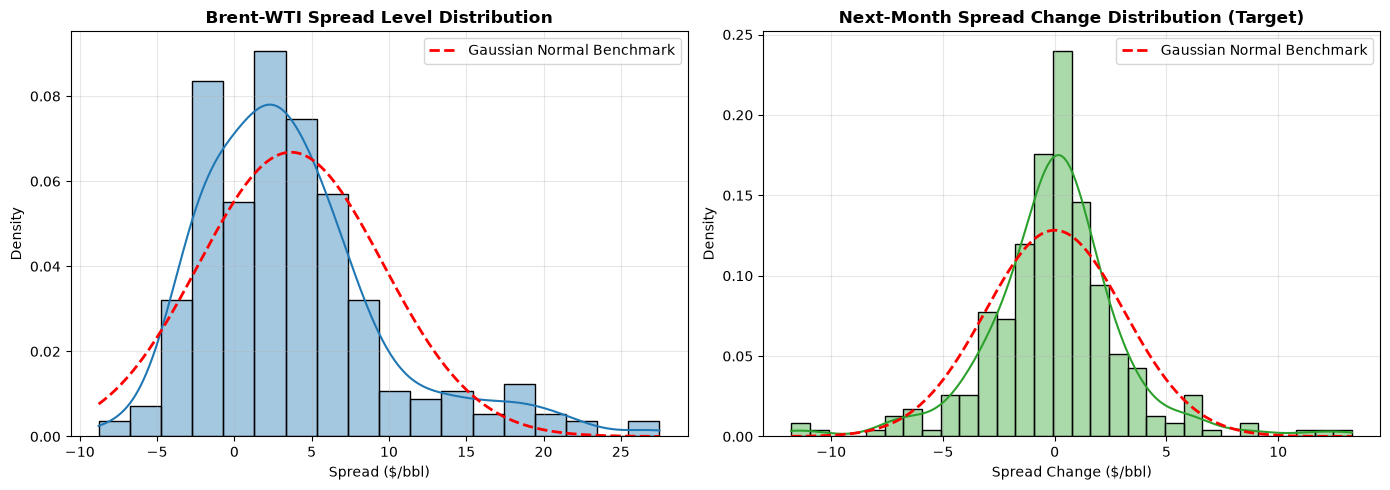

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# A. Spread Level Distribution
sns.histplot(
    model_sample["spread"].dropna(),
    kde=True,
    stat="density",
    ax=axes[0],
    color="#1f77b4",
    alpha=0.4,
)
x0 = np.linspace(model_sample["spread"].min(), model_sample["spread"].max(), 200)
axes[0].plot(
    x0,
    stats.norm.pdf(
        x0, model_sample["spread"].mean(), model_sample["spread"].std()
    ),
    "r--",
    linewidth=2,
    label="Gaussian Normal Benchmark",
)
axes[0].set_title(
    "Brent-WTI Spread Level Distribution", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Spread ($/bbl)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# B. Spread Change (Target) Distribution
sns.histplot(
    model_sample[TARGET_COL].dropna(),
    kde=True,
    stat="density",
    ax=axes[1],
    color="#2ca02c",
    alpha=0.4,
)
x1 = np.linspace(
    model_sample[TARGET_COL].min(), model_sample[TARGET_COL].max(), 200
)
axes[1].plot(
    x1,
    stats.norm.pdf(
        x1, model_sample[TARGET_COL].mean(), model_sample[TARGET_COL].std()
    ),
    "r--",
    linewidth=2,
    label="Gaussian Normal Benchmark",
)
axes[1].set_title(
    "Next-Month Spread Change Distribution (Target)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Spread Change ($/bbl)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

The figures above compare the empirical distributions of the spread level and the next month spread change target against a theoretical gaussian normal benchmark (red dashed curve).

For the first figure, the spread level is skewed and it features a long right tail stretching up to +$27.50/bbl. This long right tail visually captures the 2011-2015 period. The distribution clearly deviates from the symmetric bell curve.

For the second figure, the target variable is centered at zero, but it shows a much sharper, higher peak and fatter tails than the normal distribution. This mean that small monthly changes occur very frequently around zero, but extreme swings happen far more often than Gaussian assumptions predict.

These metrics matter because the fat tails in the target variable violate standard OLS assumptions. Therefore, this justifies using Ridge regression (to shrink outlier-driven coefficients) and tree-based models (Random Forest, LightGBM), which handle skewed, non-normal distributions much more robustly.

# 4. Forecasting Models

This section estimates forecasting models for the monthly change in the Brent-WTI spread.

The models are evaluated using a rolling-window procedure. At each date, the model is trained on a fixed number of past monthly observations and then used to predict the next observation. The training window then moves forward by one month.

This ensures that predictions are generated out-of-sample and that the chronological order of the data is respected.

We use a RidgeCV regression, Random Forest, LightGBM and Ensemble models.

## 4.1 Rolling-Window Setup

In [27]:
TRAIN_WINDOW = 120
TEST_SIZE = 1

FIRST_OOS_DATE = model_sample["date"].iloc[TRAIN_WINDOW]

TRAIN_START = model_sample["date"].iloc[0]
TRAIN_END = model_sample["date"].iloc[TRAIN_WINDOW - 1]

print("Train Start:", TRAIN_START)
print("Train End  :", TRAIN_END)
print("First OOS  :", FIRST_OOS_DATE)

Train Start: 2003-04-01 00:00:00
Train End  : 2013-03-01 00:00:00
First OOS  : 2013-04-01 00:00:00


We test two historical estimation depths:
- $W = 120$ months (10 years of training history)
- $W = 180$ months (15 years of training history)

At each month $t$, the trained model produces a single out-of-sample forecast $\hat{y}_{t+1|t}$ for month $t+1$. The training sample then rolls forward by one month, discarding the oldest observation and incorporating the newly realized data point.

Because $W=180$ requires 15 years of warm-up data, its first out-of-sample prediction occurs in April 2018. To ensure a fair comparison, the algorithms are evaluated over the identical out-of-sample window: April 1, 2018 to June 1, 2026 ($N = 99$ monthly forecasts).

## 4.2 Machine Learning algorithms

- RidgeCV: We use RidgeCV rather than a static Ridge because a fixed penalty cannot adapt to changing market regimes across time.

- Random Forest:
It applies bootstrap aggregation over decorrelated regression trees. By averaging across multiple trees trained on bootstrap samples and restricting feature selection at each split to a random subset, Random Forest reduces variance and dampens the impact of extreme outliers and fat tails identified in Table 1.

- LightGBM: It builds shallow decision trees sequentially to minimize squared prediction errors. Its leaf-wise growth with depth constraints makes it well-suited for capturing non-linear threshold effects that linear models cannot detect.

- Ensemble models: To diversify model-specific estimation errors, we evaluate three ensemble models combining predictions from RidgeCV, Random Forest, and LightGBM: an equal-weighting benchmark, an unconstrained rolling regression (Britten-Jones dynamic stacking), and a constrained rolling non-negative least squares (Positive NNLS).

We evaluate all models against three standard econometric benchmarks:
1. Naive model: $\hat{\Delta S}_{t+1} = 0$. Represents the market efficiency baseline.
2. Historical Mean
3. Univariate AR(1) 

In [28]:
TRAIN_WINDOWS = [120, 180]

# Instantiate base machine learning estimators (RidgeCV, Random Forest, LightGBM)
models = get_models()
print("Running rolling walk-forward diagnostics for base models...")
diagnostics_df, diagnostics_predictions, alphas_history = (
    run_overfitting_diagnostics(
        data=model_sample,
        feature_sets=FEATURE_SETS,
        target_col=TARGET_COL,
        models=models,
        train_windows=TRAIN_WINDOWS,
        test_size=1,
    )
)

# Generate dynamic ensembles (1/N, Mbj Unconstrained, Mbj Positive NNLS) and merge them
print("Computing dynamic rolling ensembles and appending to diagnostic results...")
diagnostics_df, diagnostics_predictions = add_ensembles_to_diagnostics(
    diagnostics_df=diagnostics_df,
    diagnostics_predictions=diagnostics_predictions,
    feature_sets=FEATURE_SETS,
    train_windows=TRAIN_WINDOWS,
)

diagnostics_df.to_csv(
    PROCESSED_DIR / "overfitting_diagnostics.csv", index=False
)

print(
    f"Rolling walk-forward diagnostics completed successfully: "
    f"{len(diagnostics_df)} configurations saved."
)

Running rolling walk-forward diagnostics for base models...
Running naive_zero       | prices_only               | train_window=120
Running historical_mean  | prices_only               | train_window=120
Running ar1              | prices_only               | train_window=120
Running ridge_cv         | prices_only               | train_window=120
Running random_forest    | prices_only               | train_window=120
Running lightgbm         | prices_only               | train_window=120
Running naive_zero       | prices_wti_fundamentals   | train_window=120
Running historical_mean  | prices_wti_fundamentals   | train_window=120
Running ar1              | prices_wti_fundamentals   | train_window=120
Running ridge_cv         | prices_wti_fundamentals   | train_window=120
Running random_forest    | prices_wti_fundamentals   | train_window=120
Running lightgbm         | prices_wti_fundamentals   | train_window=120
Running naive_zero       | prices_brent_fundamentals | train_window=120
Runn

In [29]:
COMMON_OOS_START = max(
    preds["oos"]["date"].min()
    for preds in diagnostics_predictions.values()
)

print("Common OOS Evaluation Start Date:", COMMON_OOS_START)

Common OOS Evaluation Start Date: 2018-04-01 00:00:00


Models are compared out-of-sample over the common evaluation period using standard quantitative metrics: Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), Out-of-Sample $R^2$, Linear Correlation, and Directional Accuracy (Hit Ratio).

In [30]:
common_results = []

for key, preds_dict in diagnostics_predictions.items():
    oos_preds = preds_dict["oos"].copy()
    oos_preds = oos_preds[oos_preds["date"] >= COMMON_OOS_START]

    metrics = forecast_metrics(oos_preds)

    parts = key.split("__")
    feature_set = parts[0]
    model_name = parts[1]
    train_window = int(parts[2].replace("window_", ""))

    common_results.append(
        {
            "train_window": train_window,
            "feature_set": feature_set,
            "model": model_name,
            "n_oos": len(oos_preds),
            "rmse": metrics["rmse"],
            "mae": metrics["mae"],
            "r2": metrics["r2"],
            "correlation": metrics["correlation"],
            "directional_acc": metrics["directional_accuracy"],
        }
    )

common_metrics = pd.DataFrame(common_results)

In [31]:
print("TOP FORECASTING MODELS (Sorted by OOS RMSE)")
display(
    common_metrics.sort_values("rmse").head(15)[
        [
            "train_window",
            "feature_set",
            "model",
            "rmse",
            "mae",
            "r2",
            "correlation",
            "directional_acc",
        ]
    ]
)

TOP FORECASTING MODELS (Sorted by OOS RMSE)


,train_window,feature_set,model,rmse,mae,r2,correlation,directional_acc
29,180,prices_only,lightgbm,2.934023,2.017430,0.095079,0.315159,0.565657
60,180,prices_only,ensemble_1_over_n,2.970709,2.031413,0.072308,0.303643,0.595960
35,180,prices_wti_fundamentals,lightgbm,2.975365,2.096726,0.069398,0.265250,0.545455
5,120,prices_only,lightgbm,2.980756,2.046812,0.066023,0.258654,0.595960
65,180,prices_wti_fundamentals,ensemble_mbj_positive,2.986091,2.100092,0.062676,0.265713,0.545455
28,180,prices_only,random_forest,2.989599,2.051882,0.060473,0.273289,0.575758
48,120,prices_only,ensemble_1_over_n,2.994320,2.035449,0.057503,0.252284,0.606061
63,180,prices_wti_fundamentals,ensemble_1_over_n,3.002815,2.071730,0.052147,0.267202,0.515152
3,120,prices_only,ridge_cv,3.003155,2.036666,0.051933,0.245056,0.595960
64,180,prices_wti_fundamentals,ensemble_mbj_unconstrained,3.005784,2.090703,0.050272,0.261727,0.505051


In [32]:
print("TOP FORECASTING MODELS (Sorted by Directional Accuracy)")
display(
    common_metrics.sort_values("directional_acc", ascending=False).head(15)[
        [
            "train_window",
            "feature_set",
            "model",
            "directional_acc",
            "rmse",
            "r2",
            "correlation",
        ]
    ]
)

TOP FORECASTING MODELS (Sorted by Directional Accuracy)


,train_window,feature_set,model,directional_acc,rmse,r2,correlation
40,180,prices_brent_fundamentals,random_forest,0.606061,3.071855,0.008061,0.098199
48,120,prices_only,ensemble_1_over_n,0.606061,2.994320,0.057503,0.252284
3,120,prices_only,ridge_cv,0.595960,3.003155,0.051933,0.245056
5,120,prices_only,lightgbm,0.595960,2.980756,0.066023,0.258654
27,180,prices_only,ridge_cv,0.595960,3.031003,0.034268,0.207456
39,180,prices_brent_fundamentals,ridge_cv,0.595960,3.028368,0.035947,0.197496
69,180,prices_all_fundamentals,ensemble_1_over_n,0.595960,3.015792,0.043938,0.235354
60,180,prices_only,ensemble_1_over_n,0.595960,2.970709,0.072308,0.303643
62,180,prices_only,ensemble_mbj_positive,0.585859,3.006720,0.049681,0.237580
53,120,prices_wti_fundamentals,ensemble_mbj_positive,0.585859,3.070875,0.008693,0.136686


For minimizing the forecast error, LightGBM on `prices_only` ($W=180$) achieves the best performance with the lowest RMSE and the highest $R^2$ out-of-sample. Price dynamics (mean reversion and rolling trends) provide the cleanest signal for minimizing squared errors.

For predicting movement direction, Random Forest with Brent fundamentals ($W=180$) and the 1/N ensemble on `prices_only` ($W=180$) share the highest hit ratio at 60.61%. While fundamentals add slight noise to exact point estimates, their structural trends provide strong directional signals for anticipating market turning points.

The 180-month window consistently outperforms the 120-month window across both metrics, showing that a longer historical memory stabilizes model training.

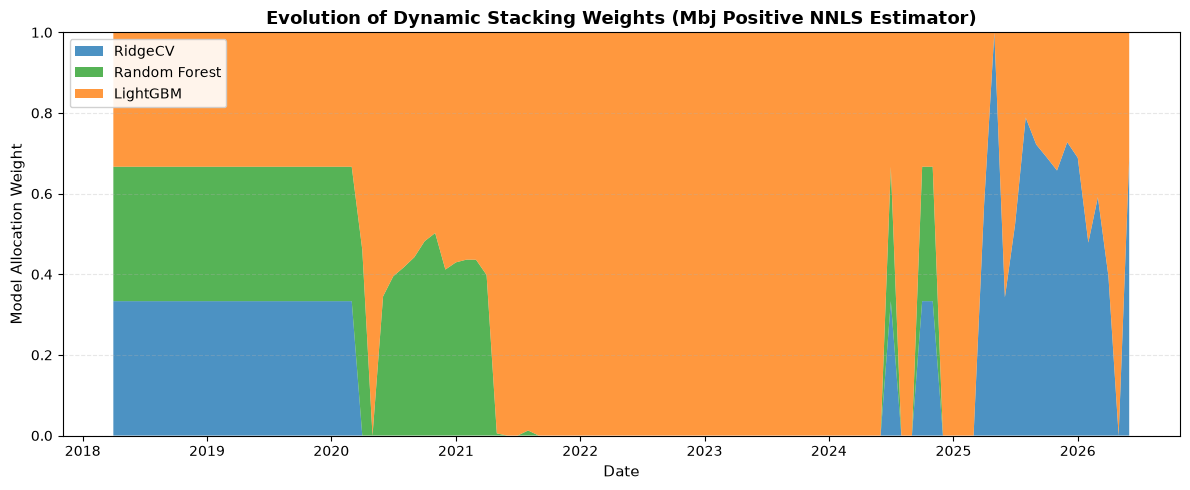

In [34]:
FEATURE_SET_STACK = "prices_wti_fundamentals"
TRAIN_WINDOW_STACK = 180

ensemble_forecasts, ensemble_weights = build_rolling_stacking(
    diagnostics_predictions=diagnostics_predictions,
    feature_set=FEATURE_SET_STACK,
    train_window=TRAIN_WINDOW_STACK,
    base_models=("ridge_cv", "random_forest", "lightgbm"),
    stack_window=60,
    min_periods=24,
)

weights_plot = ensemble_weights.copy()
if "date" not in weights_plot.columns:
    weights_plot = weights_plot.reset_index()

weights_plot["date"] = pd.to_datetime(weights_plot["date"])
weights_plot = weights_plot[weights_plot["date"] >= pd.to_datetime(COMMON_OOS_START)].sort_values("date")

plt.figure(figsize=(12, 5))
plt.stackplot(
    weights_plot["date"],
    weights_plot["weight_ridge_cv"],
    weights_plot["weight_random_forest"],
    weights_plot["weight_lightgbm"],
    labels=["RidgeCV", "Random Forest", "LightGBM"],
    colors=["#1f77b4", "#2ca02c", "#ff7f0e"],
    alpha=0.80,
)
plt.title(
    "Evolution of Dynamic Stacking Weights (Mbj Positive NNLS Estimator)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Date", fontsize=11)
plt.ylabel("Model Allocation Weight", fontsize=11)
plt.ylim(0, 1)
plt.legend(loc="upper left", framealpha=0.9)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

The dynamic stacking allocation is dominated by LightGBM throughout the out-of-sample period, capturing nearly 100% of the weight between 2021 and 2024.

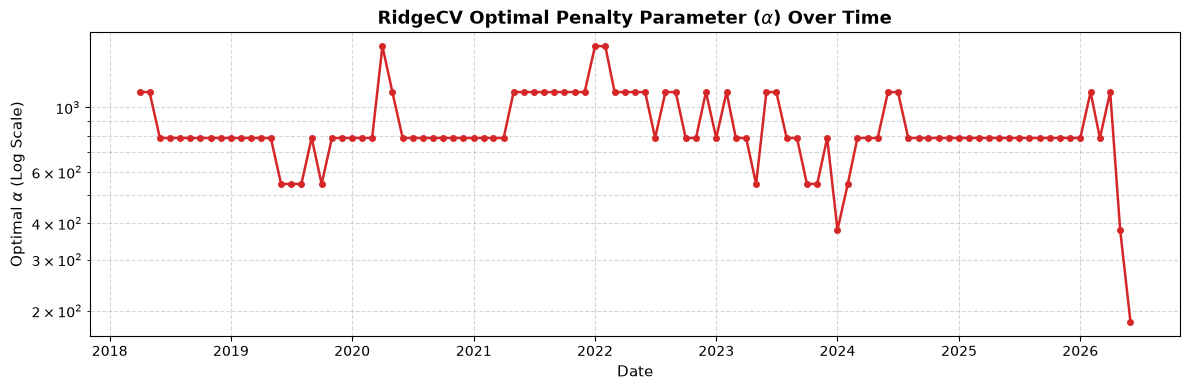

RidgeCV Alpha Summary -> Min: 183.3, Median: 784.8, Max: 1623.8


In [35]:
key_alpha = f"{FEATURE_SET_STACK}__ridge_cv__window_{TRAIN_WINDOW_STACK}"

if key_alpha in alphas_history:
    alpha_df = alphas_history[key_alpha]
    alpha_eval = alpha_df[alpha_df["date"] >= COMMON_OOS_START].copy()

    plt.figure(figsize=(12, 4))
    plt.plot(
        alpha_eval["date"],
        alpha_eval["alpha"],
        marker="o",
        markersize=4,
        color="#d62728",
        linewidth=1.8,
    )
    plt.yscale("log")
    plt.title(
        r"RidgeCV Optimal Penalty Parameter ($\alpha$) Over Time",
        fontsize=13,
        fontweight="bold",
    )
    plt.xlabel("Date", fontsize=11)
    plt.ylabel(r"Optimal $\alpha$ (Log Scale)", fontsize=11)
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    print(
        f"RidgeCV Alpha Summary -> Min: {alpha_eval['alpha'].min():.1f}, "
        f"Median: {alpha_eval['alpha'].median():.1f}, "
        f"Max: {alpha_eval['alpha'].max():.1f}"
    )

Finally, we can look at how the RidgeCV optimal penalty parameter evolves over time. The optimal penalty parameter $\alpha$ varies substantially over time, ranging from 183.3 to 1623.8 with a median of 784.8. This large variation across market regimes confirms that using RidgeCV to dynamically tune $\alpha$ at each step is much better than relying on a standard Ridge regression with a fixed penalty.

## 4.3 Feature importance

To understand what drives our model predictions, we analyze feature importance using two complementary perspectives:

1. LightGBM (Average Information Gain) measures the total reduction in squared error brought by each variable across tree splits. 

2. RidgeCV (Average Standardized Beta) shows the average directional impact of each standardized feature. A positive beta means higher values predict a widening spread, while a negative beta indicates a narrowing spread.
 
Instead of computing feature importance on a single static fit, we extract the importances at each step of our walk-forward procedure across all 99 out-of-sample models (2018–2026). The reported values are the averages across all rolling market regimes.

In [36]:
INTERP_FEATURE_SET = "prices_wti_fundamentals"
feature_cols = FEATURE_SETS[INTERP_FEATURE_SET]
TRAIN_WINDOW = 180

lgb_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    LGBMRegressor(
        n_estimators=80,
        learning_rate=0.05,
        max_depth=2,
        num_leaves=4,
        min_child_samples=15,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=1,
        verbose=-1,
    ),
)

ridge_alphas = np.exp(np.linspace(np.log(10), np.log(10000), 20))
ridge_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    RidgeCV(alphas=ridge_alphas, cv=None),
)

In [37]:
lgb_rolling_importances = []
ridge_rolling_betas = []
rolling_dates = []

df_eval = model_sample.dropna(subset=[TARGET_COL]).reset_index(drop=True)

print(f"Extracting rolling feature importances across {len(df_eval) - TRAIN_WINDOW} walk-forward windows...")

for start in range(0, len(df_eval) - TRAIN_WINDOW):
    train_idx = slice(start, start + TRAIN_WINDOW)
    test_date = df_eval["date"].iloc[start + TRAIN_WINDOW]
    
    # We only accumulate during the common out-of-sample period (2018-2026)
    if test_date < pd.to_datetime(COMMON_OOS_START):
        continue

    X_train = df_eval.iloc[train_idx][feature_cols]
    y_train = df_eval.iloc[train_idx][TARGET_COL]

    # Fit rolling LightGBM estimator
    m_lgb = clone(lgb_pipeline)
    m_lgb.fit(X_train, y_train)
    # Course formula: booster_.feature_importance(importance_type="gain")
    gain = m_lgb.named_steps["lgbmregressor"].booster_.feature_importance(importance_type="gain")
    lgb_rolling_importances.append(gain)

    # Fit rolling RidgeCV estimator
    m_ridge = clone(ridge_pipeline)
    m_ridge.fit(X_train, y_train)
    beta = m_ridge.named_steps["ridgecv"].coef_
    ridge_rolling_betas.append(beta)

    rolling_dates.append(test_date)


Extracting rolling feature importances across 99 walk-forward windows...


In [38]:
lgb_stack = np.stack(lgb_rolling_importances)
ridge_stack = np.stack(ridge_rolling_betas)

# Average importance across all out-of-sample market regimes
mean_lgb_gain = np.mean(lgb_stack, axis=0)
mean_ridge_beta = np.mean(ridge_stack, axis=0)

interp_df = pd.DataFrame({
    "Feature": feature_cols,
    "Mean_LightGBM_Gain": mean_lgb_gain,
    "Mean_Ridge_Beta": mean_ridge_beta,
})

print(f"Successfully computed average importance over {len(rolling_dates)} historical OOS models.")

Successfully computed average importance over 99 historical OOS models.


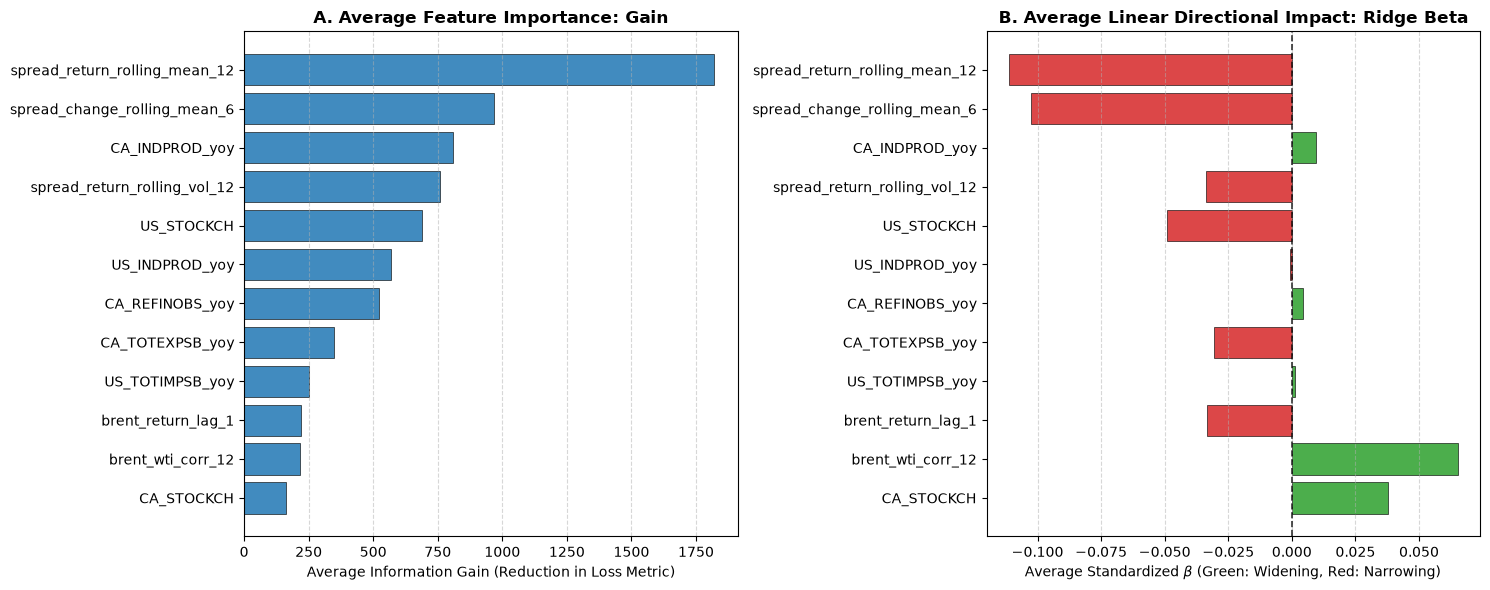

TOP 10 PREDICTORS (WALK-FORWARD AVERAGED)


,Feature,Mean_LightGBM_Gain,Mean_Ridge_Beta
4,spread_return_rolling_mean_12,1819.70,-0.1112
3,spread_change_rolling_mean_6,966.56,-0.1025
12,CA_INDPROD_yoy,809.06,0.0096
7,spread_return_rolling_vol_12,760.04,-0.0339
20,US_STOCKCH,688.32,-0.0490
18,US_INDPROD_yoy,570.45,-0.0008
13,CA_REFINOBS_yoy,523.62,0.0044
15,CA_TOTEXPSB_yoy,347.94,-0.0305
22,US_TOTIMPSB_yoy,249.64,0.0010
5,brent_return_lag_1,219.11,-0.0334


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: Average Information Gain (LightGBM)
top_lgb = (
    interp_df.sort_values("Mean_LightGBM_Gain", ascending=False)
    .head(12)
    .sort_values("Mean_LightGBM_Gain", ascending=True)
)

axes[0].barh(
    top_lgb["Feature"],
    top_lgb["Mean_LightGBM_Gain"],
    color="#1f77b4",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.85,
)
axes[0].set_title(
    "A. Average Feature Importance: Gain",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Average Information Gain (Reduction in Loss Metric)")
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

# Panel B: Average Standardized Linear Beta (RidgeCV)
top_ridge = interp_df.reindex(top_lgb.index)
colors = ["#2ca02c" if c > 0 else "#d62728" for c in top_ridge["Mean_Ridge_Beta"]]

axes[1].barh(
    top_ridge["Feature"],
    top_ridge["Mean_Ridge_Beta"],
    color=colors,
    edgecolor="black",
    linewidth=0.5,
    alpha=0.85,
)
axes[1].axvline(0, color="black", linestyle="--", alpha=0.8, linewidth=1.2)
axes[1].set_title(
    "B. Average Linear Directional Impact: Ridge Beta",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel(
    r"Average Standardized $\beta$ (Green: Widening, Red: Narrowing)"
)
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Tabular summary
print("TOP 10 PREDICTORS (WALK-FORWARD AVERAGED)")
display(
    interp_df.sort_values("Mean_LightGBM_Gain", ascending=False)
    .head(10)
    .style.format({"Mean_LightGBM_Gain": "{:.2f}", "Mean_Ridge_Beta": "{:.4f}"})
    .background_gradient(subset=["Mean_LightGBM_Gain"], cmap="Blues")
)

The two most important predictors are 12 and 6 month rolling spread averages. They have a negative Ridge betas, that shows that when the spread widens excessively, physical arbitrage forces it back down toward equilibrium.

Canadian production ranks 3rd overall  with a positive coefficient. This means that rising Canadian pipeline flows increase inland supply, depressing WTI and widening the spread. This finding is directly consistent with Sifat, Zarei, and Mand (2022) (Revisiting WTI-Brent spread and its drivers).

Monthly US stock changes rank 5th with a negative beta, showing that domestic stock accumulation directly depresses WTI relative to Brent.

# 5. Portfolio construction

# 6. Conclusion

Finally, the conclusive synthesis should recapitulate the primary findings, consider external elements that may influence the results, and hint at potential directions for further investigative work.